# 02 · Recommendation Experiment with Welch's t-test

**Portfolio recreation · synthetic data · reproducible**

**Question:** Does a simulated content recommendation feature increase mean articles read per user? We compare independent groups with Welch's unequal-variance t-test.

In [1]:
from pathlib import Path
import sys
root = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from IPython.display import Image, display
from src.recommendation_ab import simulate_article_reads, welch_test, evaluate
from src.visualize import save_reco_chart


## 1 · Create the experiment

In [2]:
result = evaluate()
print(f"Control users: {result['n_control']:,}")
print(f"Treatment users: {result['n_treatment']:,}")
print(f"Mean reads (A): {result['control_mean']:.3f}")
print(f"Mean reads (B): {result['treatment_mean']:.3f}")
print(f"Relative uplift: {result['relative_lift']:.2%}")

Control users: 2,058
Treatment users: 2,120
Mean reads (A): 4.817
Mean reads (B): 5.283
Relative uplift: 9.69%


## 2 · Hypothesis test

The null is equal population means. Use a **two-sided** hypothesis, sample variance estimates, Welch–Satterthwaite degrees of freedom, and the Student t distribution.

Welch t-statistic: -6.7039
Degrees of freedom: 4174.20
Two-sided p-value: 2.3011412e-11
Reject H0 at alpha=0.05: True


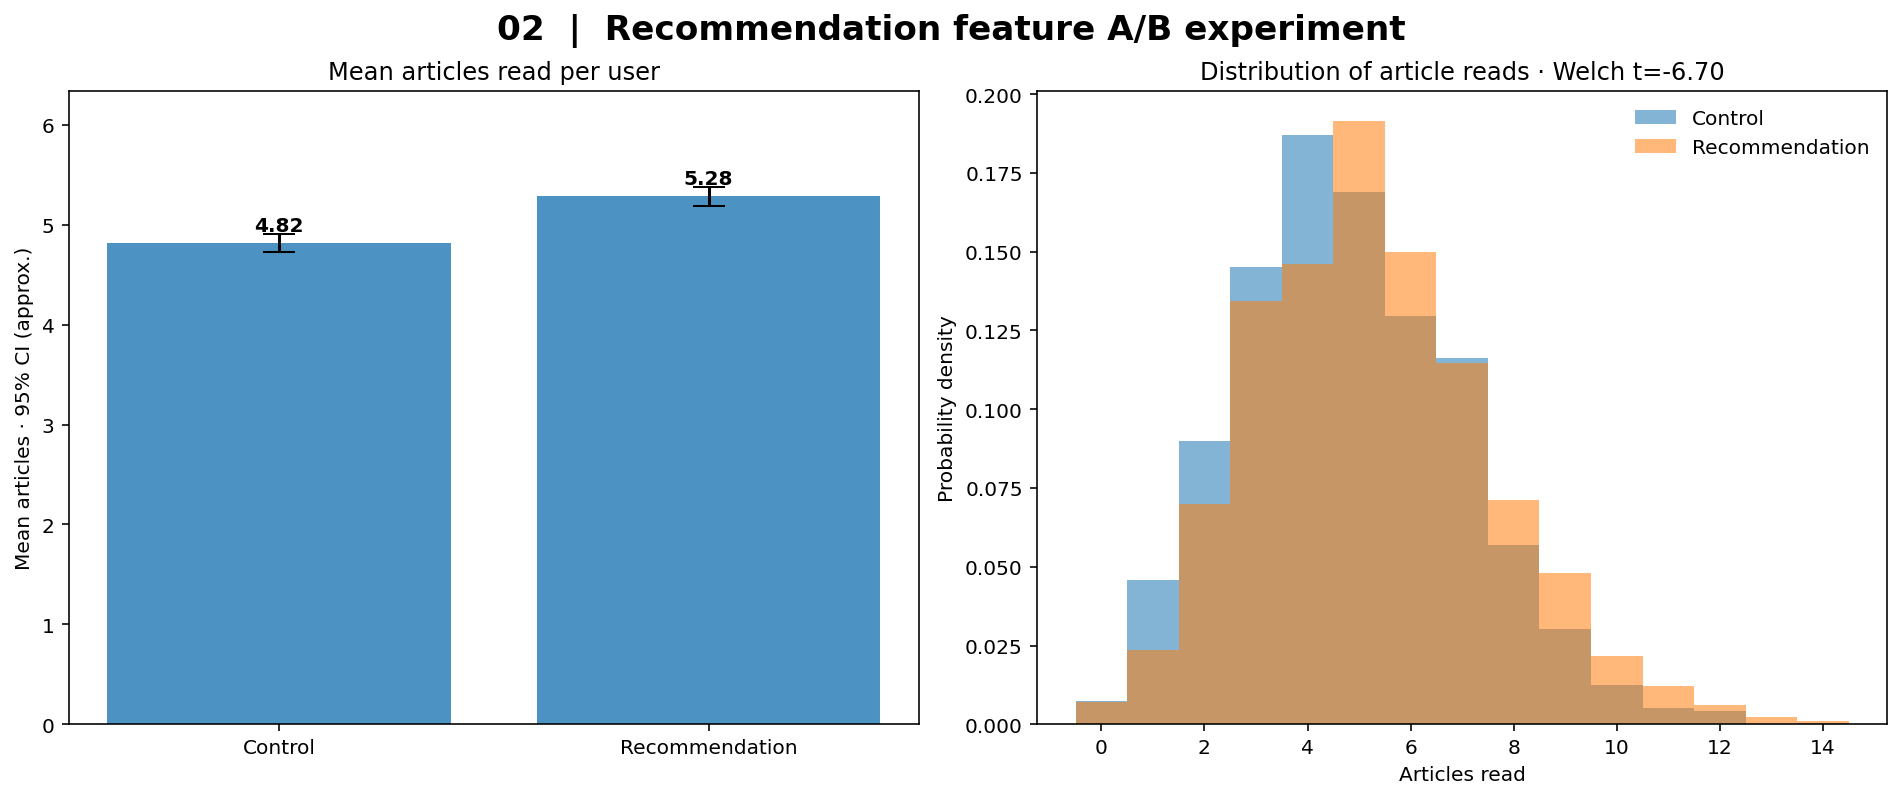

In [3]:
print(f"Welch t-statistic: {result['t_statistic']:.4f}")
print(f"Degrees of freedom: {result['degrees_of_freedom']:.2f}")
print(f"Two-sided p-value: {result['p_value']:.8g}")
print('Reject H0 at alpha=0.05:', result['reject_null'])
chart_path, _ = save_reco_chart()
display(Image(filename=str(chart_path)))

## Takeaways and limitations

- An observed increase in means is not sufficient by itself; the test quantifies evidence against equal means.
- The data are independent **simulated count observations**, not a production experiment.
- A real A/B test should predefine metrics and analysis, randomise units, consider variance and practical effect size, and avoid peeking or stopping early based on p-values alone.